# 01: Exploratory Data Analysis: North Carolina Home Prices

**Goal of this notebook:** understand the data *before* modeling, which answers two questions:
1. What does the data look like? (distributions, relationships, problems) This becomes the report's **Data** section.
2. What does preprocessing need to fix? (skewed target, outliers, missing values)

Data: realtor.com "USA Real Estate Dataset" (Kaggle), filtered to North Carolina homes that are for sale or sold.
Techniques follow the course's Data Exploration homework (null checks, `describe`, boxplots, log transform, scatter plots, correlation matrix).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))
from load_data import load_nc_homes
from plot_style import apply_style, save, BLUE, ORANGE, TEXT_2, SEQ_BLUE, DIVERGING

apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
dollars = mtick.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M" if x >= 1e6 else f"${x/1e3:.0f}k")

## 1. Loading and filtering

Starting from 2.2M US listings, we keep:
- **North Carolina** only.
- **`for_sale` and `sold`** listings. `ready_to_build` (mostly land or unbuilt homes) is dropped. `status` stays as a feature.
- Rows with **price, bed, bath and house_size** present. Rows missing these are mostly **land lots**, which aren't homes.
- **No duplicates**: the same listing posted more than once would leak between train and test sets.

In [2]:
nc, steps = load_nc_homes()
steps

,step,rows
0,All US listings,2226382
1,North Carolina only,85745
2,Status for_sale or sold (drop ready_to_build),84591
3,"Has price, bed, bath, house_size (drop land lots)",42946
4,Duplicates removed,40767


In [3]:
print(nc.shape)
nc.head()

(40767, 12)


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,"95,286.00",for_sale,"158,000.00",3.00,2.00,NaN,"1,543,016.00",Elizabeth City,North Carolina,27909,"1,178.00",2021-02-23
1,"15,924.00",for_sale,"335,000.00",3.00,2.00,NaN,"143,679.00",South Mills,North Carolina,27976,"1,656.00",2020-01-17
2,"99,627.00",for_sale,"360,000.00",4.00,3.00,NaN,"415,299.00",South Mills,North Carolina,27976,"2,100.00",2020-03-03
3,"53,016.00",for_sale,"399,900.00",4.00,3.00,0.98,"132,701.00",South Mills,North Carolina,27976,"2,641.00",2021-06-09
4,"1,047.00",for_sale,"400,000.00",3.00,3.00,NaN,"222,129.00",Moyock,North Carolina,27958,"2,600.00",2020-08-31


In [4]:
nc.info()

<class 'pandas.DataFrame'>
RangeIndex: 40767 entries, 0 to 40766
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   brokered_by     40366 non-null  float64
 1   status          40767 non-null  str    
 2   price           40767 non-null  float64
 3   bed             40767 non-null  float64
 4   bath            40767 non-null  float64
 5   acre_lot        35340 non-null  float64
 6   street          40759 non-null  float64
 7   city            40767 non-null  str    
 8   state           40767 non-null  str    
 9   zip_code        40766 non-null  string 
 10  house_size      40767 non-null  float64
 11  prev_sold_date  28874 non-null  str    
dtypes: float64(7), str(4), string(1)
memory usage: 3.7 MB


## 2. Missing values

After dropping land lots, which columns still have gaps?

,missing,percent
prev_sold_date,11893,29.20
acre_lot,5427,13.30
brokered_by,401,1.00
street,8,0.00
zip_code,1,0.00
bed,0,0.00
status,0,0.00
price,0,0.00
city,0,0.00
bath,0,0.00


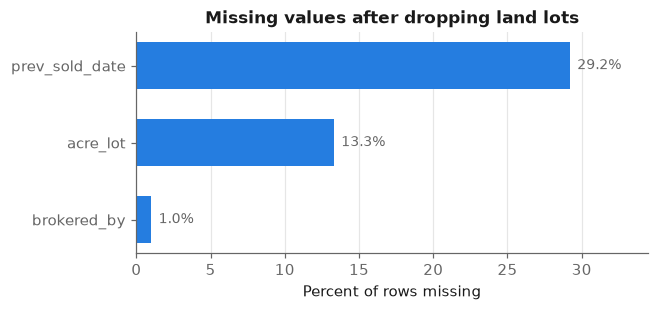

In [5]:
missing = nc.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(nc) * 100).round(1)
display(pd.DataFrame({"missing": missing, "percent": missing_pct}))

m = missing_pct[missing_pct > 0].sort_values()
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(m.index, m.values, color=BLUE, height=0.6)
for y, v in enumerate(m.values):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", color=TEXT_2, fontsize=9)
ax.set_xlabel("Percent of rows missing")
ax.set_title("Missing values after dropping land lots")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(m.max() * 1.18, 5))
save(fig, "fig03_missing_values")
plt.show()

## 3. Summary statistics and outliers

In [6]:
num_cols = ["price", "bed", "bath", "house_size", "acre_lot"]
nc[num_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

,price,bed,bath,house_size,acre_lot
count,"40,767.00","40,767.00","40,767.00","40,767.00","35,340.00"
mean,"430,747.97",3.24,2.66,"2,054.08",7.61
std,"442,814.58",1.16,1.21,"4,238.10",595.63
min,0.00,1.00,1.00,209.00,0.00
1%,"64,900.00",1.00,1.00,664.66,0.02
25%,"229,900.00",3.00,2.00,"1,350.00",0.20
50%,"335,000.00",3.00,3.00,"1,800.00",0.35
75%,"475,000.00",4.00,3.00,"2,429.00",0.68
99%,"2,198,340.00",6.00,6.00,"5,753.34",19.21
max,"14,000,000.00",90.00,54.00,"800,900.00","100,000.00"


In [7]:
# Suspicious values: candidates for removal in preprocessing
checks = {
    "price < $10,000": (nc.price < 10_000).sum(),
    "price > $5,000,000": (nc.price > 5_000_000).sum(),
    "house_size < 300 sqft": (nc.house_size < 300).sum(),
    "house_size > 15,000 sqft": (nc.house_size > 15_000).sum(),
    "bed > 10": (nc.bed > 10).sum(),
    "bath > 10": (nc.bath > 10).sum(),
    "acre_lot > 100": (nc.acre_lot > 100).sum(),
}
pd.Series(checks, name="rows")

price < $10,000              4
price > $5,000,000          38
house_size < 300 sqft        9
house_size > 15,000 sqft    11
bed > 10                    39
bath > 10                   43
acre_lot > 100              45
Name: rows, dtype: int64

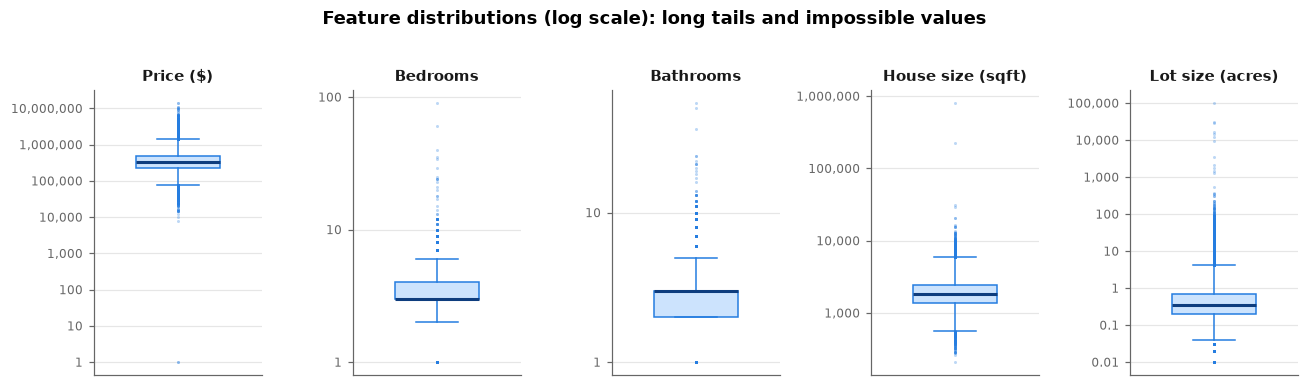

In [8]:
# Boxplots of log10(value): a linear axis gets squashed by the extreme values.
# The box/whiskers are computed on the log values, then ticks are relabeled in real units.
labels = {"price": "Price (\\$)", "bed": "Bedrooms", "bath": "Bathrooms",
          "house_size": "House size (sqft)", "acre_lot": "Lot size (acres)"}
fig, axes = plt.subplots(1, 5, figsize=(12, 3.4))
for ax, col in zip(axes, num_cols):
    vals = nc[col].dropna()
    vals = np.log10(vals[vals > 0])
    lo, hi = int(np.floor(vals.min())), int(np.ceil(vals.max()))
    ticks = range(lo, hi + 1)
    ax.set_yticks(list(ticks))
    ax.set_yticklabels([f"{10**t:,.0f}" if t >= 0 else f"{10**t:g}" for t in ticks], fontsize=8)
    ax.boxplot(vals, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#cce3fd", edgecolor=BLUE),
               medianprops=dict(color="#0e3d7e", linewidth=2),
               whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
               flierprops=dict(marker="o", markersize=2, markerfacecolor=BLUE,
                               markeredgecolor="none", alpha=0.3))
    ax.set_title(labels[col], fontsize=10)
    ax.set_xticks([])
fig.suptitle("Feature distributions (log scale): long tails and impossible values",
             fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "fig02_boxplots")
plt.show()

## 4. The target: price distribution

Like `area` in the Data Exploration homework, prices are right-skewed: most homes cluster around a few hundred thousand dollars, with a long tail of multi-million-dollar homes.
A log transform pulls that tail in, which helps linear models: they assume errors are spread evenly, and on a log scale an error means "X% too high" instead of "$X too high".

Skewness of price:      7.75
Skewness of log(price): -0.11
Median $335,000 | mean $430,759  (mean > median means right skew)


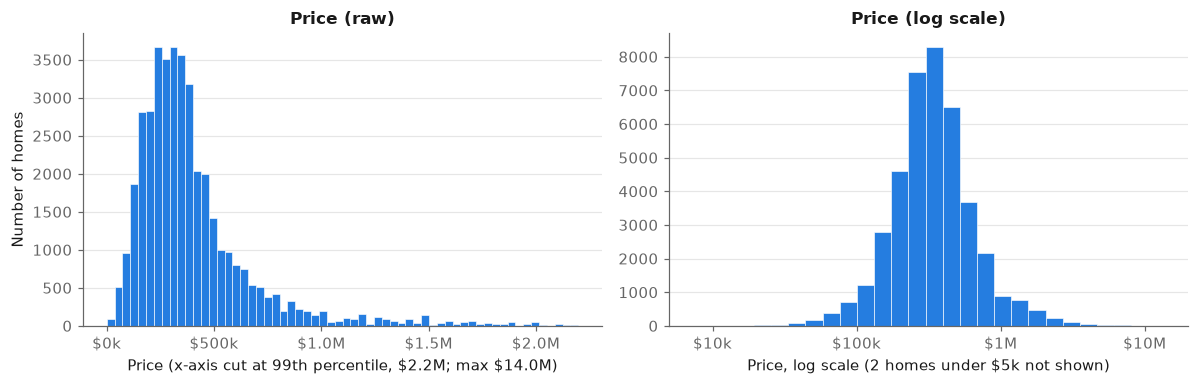

In [9]:
price = nc.price[nc.price > 0]
print(f"Skewness of price:      {price.skew():.2f}")
print(f"Skewness of log(price): {np.log(price).skew():.2f}")
print(f"Median ${price.median():,.0f} | mean ${price.mean():,.0f}  (mean > median means right skew)")

cut = price.quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(price[price <= cut], bins=60, color=BLUE, edgecolor="white", linewidth=0.4)
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_title("Price (raw)")
axes[0].set_xlabel(f"Price (x-axis cut at 99th percentile, \\${cut/1e6:.1f}M; max \\${price.max()/1e6:.1f}M)")
axes[0].set_ylabel("Number of homes")

axes[1].hist(np.log10(price), bins=60, color=BLUE, edgecolor="white", linewidth=0.4)
ticks = [1e4, 1e5, 1e6, 1e7]
axes[1].set_xticks(np.log10(ticks))
axes[1].set_xticklabels(["$10k", "$100k", "$1M", "$10M"])
axes[1].set_xlim(np.log10(5e3), np.log10(2e7))
axes[1].set_title("Price (log scale)")
axes[1].set_xlabel(f"Price, log scale ({(price < 5e3).sum()} homes under \\$5k not shown)")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "fig01_price_distribution")
plt.show()

## 5. Price vs. house size

House size is expected to be the strongest single predictor. With about 40k homes a scatter plot turns into a blob, so this uses a **hexbin** (darker cell = more homes). Both axes are log scale.
Obvious data errors (price < $10k, size outside 300 to 15,000 sqft) are hidden here only for readability.

Plotted 40,743 of 40,767 homes
Correlation price vs size, raw data (all rows): 0.17
Correlation log(price) vs log(size), plotted rows: 0.70


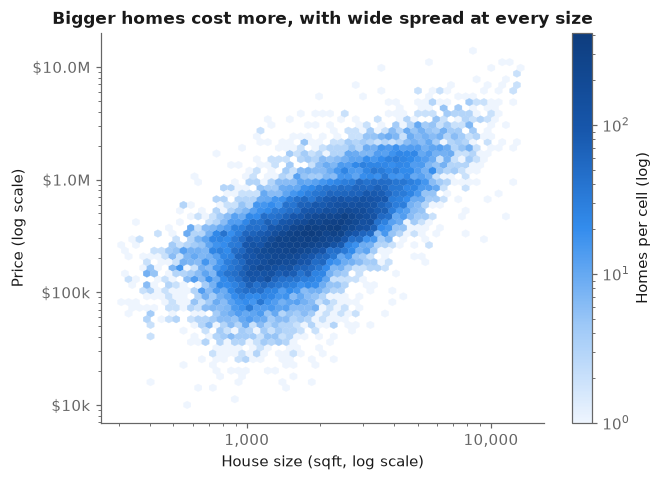

In [10]:
view = nc[(nc.price >= 10_000) & nc.house_size.between(300, 15_000)]
print(f"Plotted {len(view):,} of {len(nc):,} homes")
r_raw = nc[["price", "house_size"]].corr().iloc[0, 1]
r_log = np.corrcoef(np.log(view.price), np.log(view.house_size))[0, 1]
print(f"Correlation price vs size, raw data (all rows): {r_raw:.2f}")
print(f"Correlation log(price) vs log(size), plotted rows: {r_log:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4.6))
hb = ax.hexbin(view.house_size, view.price, gridsize=55, xscale="log", yscale="log",
               cmap=SEQ_BLUE, mincnt=1, bins="log", linewidths=0.2)
ax.yaxis.set_major_formatter(dollars)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlabel("House size (sqft, log scale)")
ax.set_ylabel("Price (log scale)")
ax.set_title("Bigger homes cost more, with wide spread at every size")
ax.grid(False)
cb = fig.colorbar(hb, ax=ax)
cb.set_label("Homes per cell (log)")
save(fig, "fig04_price_vs_size")
plt.show()

## 6. Price by bedrooms and bathrooms

Median (not mean) price per group, because medians aren't dragged around by a few mansions. The number on each bar is the group size.

,median,size
bed_grp,,
1,"220,000.00",742
2,"235,000.00",5884
3,"300,000.00",21409
4,"422,030.00",9699
5,"575,000.00",2361
6,"862,700.00",422
7+,"1,499,500.00",246


,median,size
bath_grp,,
1,"170,000.00",3894
2,"265,000.00",16223
3,"375,000.00",14275
4,"589,900.00",4337
5,"925,000.00",1215
6+,"1,599,900.00",819


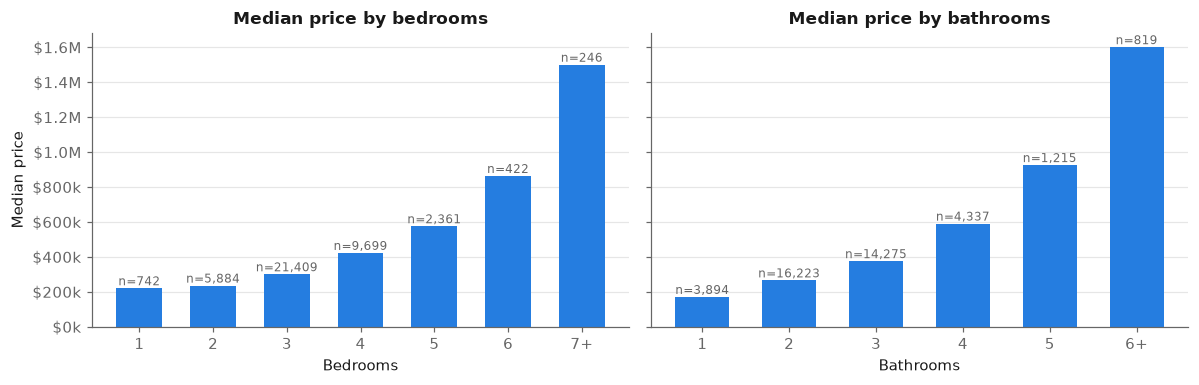

In [11]:
d = nc[nc.price >= 10_000].copy()
d["bed_grp"] = d.bed.clip(upper=7).astype(int).astype(str).replace({"7": "7+"})
d["bath_grp"] = d.bath.clip(upper=6).astype(int).astype(str).replace({"6": "6+"})
bed = d.groupby("bed_grp").price.agg(["median", "size"])
bath = d.groupby("bath_grp").price.agg(["median", "size"])
display(bed, bath)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, tbl, xl in [(axes[0], bed, "Bedrooms"), (axes[1], bath, "Bathrooms")]:
    ax.bar(tbl.index, tbl["median"], color=BLUE, width=0.62)
    for x, (m, n) in enumerate(zip(tbl["median"], tbl["size"])):
        ax.text(x, m, f"n={n:,}", ha="center", va="bottom", fontsize=8, color=TEXT_2)
    ax.set_xlabel(xl)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Median price")
axes[0].yaxis.set_major_formatter(dollars)
axes[0].set_title("Median price by bedrooms")
axes[1].set_title("Median price by bathrooms")
fig.tight_layout()
save(fig, "fig05_price_by_beds_baths")
plt.show()

## 7. Location: price by city

The dataset's finest location is the ZIP code (there are no coordinates). This compares the 10 cities with the most homes on two measures, in two separate panels, since they're on different scales:
- **median price**, the typical home's cost
- **median price per sqft**, cost per square foot, which removes the effect of home size

,homes,median_price,median_ppsf
city,,,
Fayetteville,1033,"200,000.00",122.26
Greenville,675,"209,900.00",124.58
Jacksonville,1340,"212,250.00",127.95
New Bern,650,"289,000.00",141.37
Gastonia,616,"249,900.00",163.23
Leland,669,"341,640.00",183.51
Wilmington,1239,"384,900.00",205.11
Charlotte,6236,"360,000.00",212.57
Raleigh,708,"427,000.00",229.37


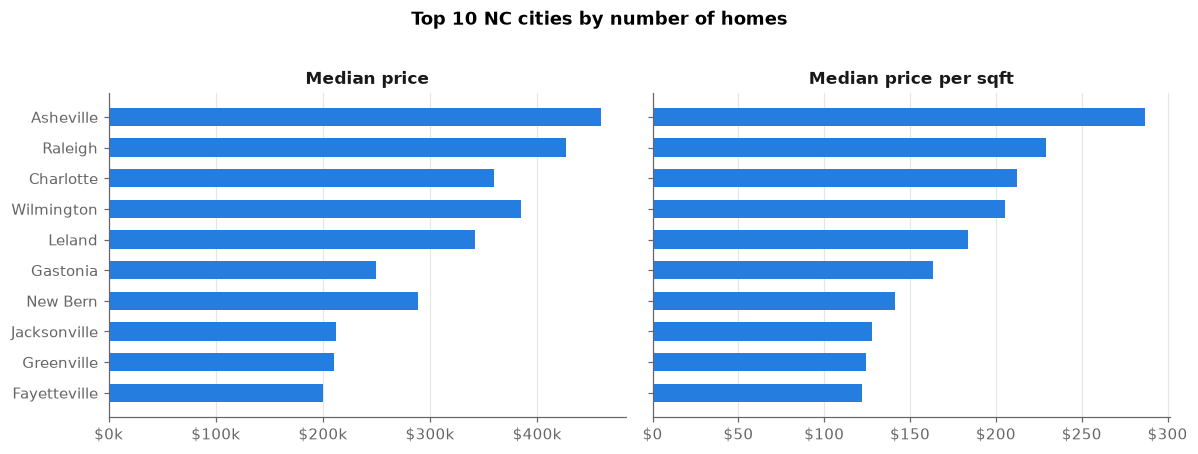

In [12]:
d = nc[(nc.price >= 10_000) & nc.house_size.between(300, 15_000)].copy()
d["ppsf"] = d.price / d.house_size
top = d.city.value_counts().head(10).index
city = (d[d.city.isin(top)].groupby("city")
        .agg(homes=("price", "size"), median_price=("price", "median"), median_ppsf=("ppsf", "median"))
        .sort_values("median_ppsf"))
display(city)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].barh(city.index, city.median_price, color=BLUE, height=0.6)
axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_title("Median price")
axes[1].barh(city.index, city.median_ppsf, color=BLUE, height=0.6)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:,.0f}"))
axes[1].set_title("Median price per sqft")
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle("Top 10 NC cities by number of homes", fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "fig06_price_by_city")
plt.show()

727 ZIP codes | median 17 homes per ZIP | 281 ZIPs (39%) have fewer than 10 homes
ZIP median $/sqft ranges from $16 to $1,290


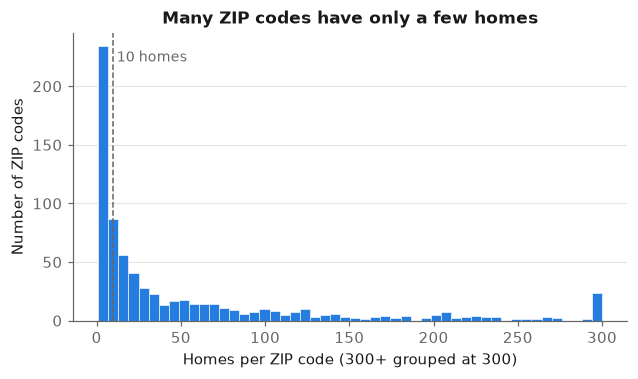

In [13]:
# ZIP codes: how many homes each has. Matters for the ZIP $/sqft feature,
# since small ZIPs give unreliable medians.
zc = d.zip_code.value_counts()
print(f"{len(zc)} ZIP codes | median {zc.median():.0f} homes per ZIP | "
      f"{(zc < 10).sum()} ZIPs ({(zc < 10).mean():.0%}) have fewer than 10 homes")
zip_ppsf = d.groupby("zip_code").ppsf.median()
print(f"ZIP median $/sqft ranges from ${zip_ppsf.min():,.0f} to ${zip_ppsf.max():,.0f}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(zc.clip(upper=300), bins=50, color=BLUE, edgecolor="white", linewidth=0.4)
ax.axvline(10, color=TEXT_2, linestyle="--", linewidth=1)
ax.text(12, ax.get_ylim()[1] * 0.9, "10 homes", color=TEXT_2, fontsize=9)
ax.set_xlabel("Homes per ZIP code (300+ grouped at 300)")
ax.set_ylabel("Number of ZIP codes")
ax.set_title("Many ZIP codes have only a few homes")
ax.grid(axis="x", visible=False)
save(fig, "fig09_homes_per_zip")
plt.show()

## 8. For sale vs. sold

The data mixes asking prices (`for_sale`) and sale prices (`sold`). Do they differ?

,homes,median_price,median_size,median_beds
status,,,,
for_sale,24458,"353,720.00","1,890.50",3.00
sold,16305,"300,000.00","1,664.00",3.00


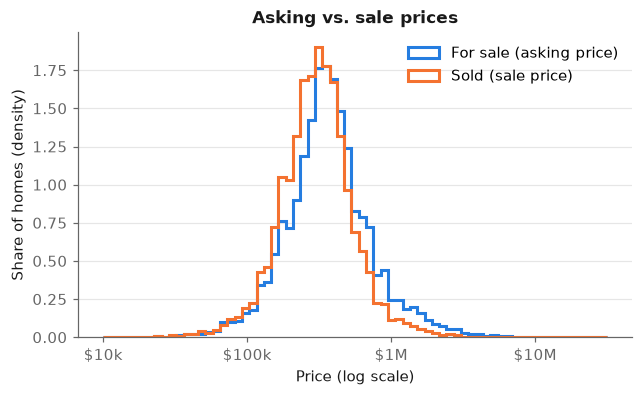

In [14]:
d = nc[nc.price >= 10_000]
display(d.groupby("status").agg(homes=("price", "size"), median_price=("price", "median"),
                                median_size=("house_size", "median"), median_beds=("bed", "median")))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bins = np.linspace(4, 7.5, 70)
for status, color, label in [("for_sale", BLUE, "For sale (asking price)"),
                             ("sold", ORANGE, "Sold (sale price)")]:
    ax.hist(np.log10(d[d.status == status].price), bins=bins, histtype="step",
            linewidth=2, color=color, label=label, density=True)
ticks = [1e4, 1e5, 1e6, 1e7]
ax.set_xticks(np.log10(ticks))
ax.set_xticklabels(["$10k", "$100k", "$1M", "$10M"])
ax.set_xlabel("Price (log scale)")
ax.set_ylabel("Share of homes (density)")
ax.set_title("Asking vs. sale prices")
ax.legend()
ax.grid(axis="x", visible=False)
save(fig, "fig07_for_sale_vs_sold")
plt.show()

## 9. Correlation matrix

Correlation measures how strongly two numbers move together in a straight line, from -1 to +1.
Price, size and lot size are log-transformed first. Otherwise a few extreme values would dominate, as the raw vs. log comparison shows.

,corr with raw price (all rows)
price,1.00
bed,0.38
bath,0.59
house_size,0.17
acre_lot,0.00


,log_price,log_house_size,bed,bath,log_acre_lot,sold
log_price,1.00,0.70,0.42,0.64,0.19,-0.14
log_house_size,0.70,1.00,0.62,0.74,0.17,-0.13
bed,0.42,0.62,1.00,0.69,0.02,-0.09
bath,0.64,0.74,0.69,1.00,0.06,-0.11
log_acre_lot,0.19,0.17,0.02,0.06,1.00,-0.09
sold,-0.14,-0.13,-0.09,-0.11,-0.09,1.00


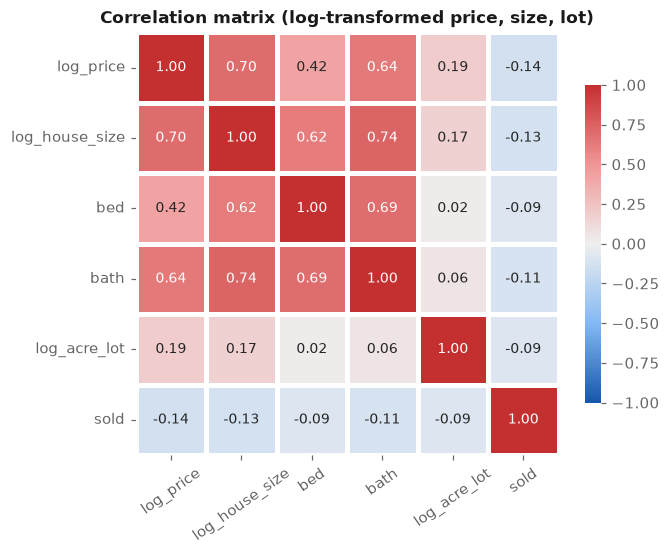

In [15]:
d = nc[(nc.price >= 10_000) & nc.house_size.between(300, 15_000)].copy()
d["log_price"] = np.log(d.price)
d["log_house_size"] = np.log(d.house_size)
d["log_acre_lot"] = np.log1p(d.acre_lot)
d["sold"] = (d.status == "sold").astype(int)

raw_corr = nc[["price", "bed", "bath", "house_size", "acre_lot"]].corr()["price"]
cols = ["log_price", "log_house_size", "bed", "bath", "log_acre_lot", "sold"]
corr = d[cols].corr()
display(pd.DataFrame({"corr with raw price (all rows)": raw_corr}))
display(corr)

fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=DIVERGING, vmin=-1, vmax=1, center=0,
            square=True, linewidths=2, linecolor="white", cbar_kws={"shrink": 0.75},
            annot_kws={"size": 9}, ax=ax)
ax.set_title("Correlation matrix (log-transformed price, size, lot)")
ax.tick_params(axis="x", rotation=35)
save(fig, "fig08_correlation_matrix")
plt.show()

## 10. Summary of findings

1. **Data after filtering:** 40,767 NC homes (24,462 for sale, 16,305 sold), down from 85,745 NC listings. Dropped: `ready_to_build`, land lots (missing bed/bath/size), and duplicates.
2. **Time period:** every *sold* home sold between **Oct 2021 and Apr 2022**, and the newest listing date is June 2022. The data is a snapshot from about **mid-2022**.
3. **Missing values:** `prev_sold_date` 29% (and for sold homes it's the sale date, so it can't be a feature without leaking), `acre_lot` 13% (needs filling), `brokered_by` 1% (an anonymized ID, so drop it).
4. **The target is heavily right-skewed:** skewness 7.75 raw vs. **-0.11 after a log transform**, and the mean ($431k) is far above the median ($335k). So: **predict log(price)**.
5. **Impossible values exist:** prices down to $0, a 800,900 sqft "house", 90 bedrooms, 54 baths, 100,000-acre lots. These are only about 200 rows, but they wreck correlations: raw price vs. size correlation is **0.17**, but log vs. log it's **0.70**.
6. **Size is the strongest predictor** (r = 0.70 with log price), then baths (0.64) and beds (0.42). Lot size is weak (0.19).
7. **Beds, baths and size overlap heavily** (r = 0.62 to 0.74). Linear regression may give odd per-feature coefficients, which is one reason to try **Ridge**.
8. **Location matters a lot:** median $/sqft runs from $122 (Fayetteville) to $287 (Asheville), 2.3×. ZIP medians run from $16 to $1,290 per sqft. 39% of ZIPs have fewer than 10 homes, so ZIP medians need smoothing.
9. **Sold homes are cheaper** (median $300k vs. $354k asking), but they're also smaller (1,664 vs. 1,891 sqft), so size explains part of the gap. Keep `status` as a feature.